# 02 — Calibration (development experiment) and preflight

**Purpose.** Choose the neural optimisation settings *once*, on data the main study never sees, and freeze them.

* Separate **development seeds** and a separate **calibration selection set** of paths (never the test set used in notebook 03).
  Because this set is used to *choose* settings, its values are not an independent performance claim.
* Selection-rule variants: sorted+payoff and raw+payoff. **Diagnostic variant:** plain raw (no payoff, no sorting) — the hardest to train.
  It is calibrated too, but only as saturation evidence: it does not influence the frozen settings, so the main comparison with LSM is not
  burdened with the step budget of the weakest variant.
* **Saturation diagnostic:** does raising the step limit still improve the policy value? This is *empirical training saturation*, not proof of convergence to the optimal policy.
* A **pre-specified selection rule** (section 3) writes `frozen_settings.json`. Notebook 03 uses exactly these settings for every variant and seed,
  so the 2×2 ablation compares representations *under a common training protocol* (Claim A). Whether plain raw catches up with more steps (Claim B) is read from section 2.
* Development cost is recorded twice: summed model-fitting time and total elapsed time (including simulation and evaluation).

Section 4 is the **preflight** (opt-in): set `RUN_PREFLIGHT = True` once, deliberately, before the full main study.

The loop saves after every fit and resumes if interrupted. Full mode takes roughly 25–35 minutes on a laptop.

In [1]:
MODE = "quick"   # "quick" = smoke test (minutes, numbers are NOT results) | "full" = research run

import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stopping import *          # all methods live in stopping.py (one file, read top to bottom)

print("Thread limits:", limit_threads(1))   # NumPy/BLAS AND PyTorch single-threaded: fair CPU timing
BASE = CONFIG[MODE]["base_seed"]
OUT = results_dir(MODE)                     # results/quick or results/full
print("Mode:", MODE, "| results ->", OUT)
cal = CONFIG[MODE]["calibration"]
cal

Thread limits: {'torch_threads': 1, 'blas': ['openblas:1', 'openblas:1', 'openmp:1']}
Mode: quick | results -> results/quick


{'budgets': [500, 2000],
 'dev_seeds': [100, 101],
 'variants': ['sorted+payoff', 'raw+payoff'],
 'diagnostic_variants': ['raw'],
 'max_steps': [50, 150],
 'lrs': [0.001, 0.003],
 'batch': 256,
 'val': 1000,
 'selection_set': 20000,
 'tolerance': 0.05}

## 1. Development grid
Each row is one policy (neural, or tuned LSM for the same data) evaluated on the calibration selection set. `row_wall_s` is the elapsed time of that row (simulation + fitting + evaluation).

In [ ]:
opt = paper_max_call(5)
ref = reference_for(opt)
selection_set = gbm_paths(opt, cal["selection_set"], seed_for(BASE, "holdout", 5))
cal_path = calibration_path(OUT, MODE)
print("Provenance-checked calibration:", cal_path)
done = pd.read_csv(cal_path) if cal_path.exists() else pd.DataFrame()
def is_done(**key):
    if done.empty: return False
    mask = np.ones(len(done), bool)
    for k, v in key.items(): mask &= (done[k] == v).to_numpy()
    return mask.any()

CAL_COLUMNS = ["method", "variant", "role", "budget", "dev_seed", "lr", "max_steps", "selection_value",
               "selection_unguarded", "n_guarded", "at_limit_share", "fit_s", "row_wall_s"]
def save(row):   # fixed column order, so appended rows always line up with the header
    pd.DataFrame([row])[CAL_COLUMNS].to_csv(cal_path, mode="a", header=not cal_path.exists(), index=False)

all_variants = cal["variants"] + cal["diagnostic_variants"]
wall0 = time.perf_counter()
for budget in cal["budgets"]:
    for dev_seed in cal["dev_seeds"]:
        t_row = time.perf_counter()
        train = gbm_paths(opt, budget, seed_for(BASE, "train", 5, dev_seed))
        val = gbm_paths(opt, cal["val"], seed_for(BASE, "val", 5, dev_seed))
        if not is_done(method="lsm", budget=budget, dev_seed=dev_seed):
            lsm, _ = select_lsm(opt, train, val)
            save(dict(method="lsm", variant="lsm", role="reference", budget=budget, dev_seed=dev_seed, lr=np.nan, max_steps=np.nan,
                      selection_value=discounted_payoffs(opt, selection_set, lsm)[0].mean(),
                      selection_unguarded=discounted_payoffs(opt, selection_set, lsm, False)[0].mean(),
                      n_guarded=lsm.n_guarded(), at_limit_share=np.nan, fit_s=lsm.info["selection_s"],
                      row_wall_s=time.perf_counter() - t_row))
        for variant in all_variants:
            for lr in cal["lrs"]:
                for steps in cal["max_steps"]:
                    key = dict(method="nn", variant=variant, budget=budget, dev_seed=dev_seed, lr=lr, max_steps=steps)
                    if is_done(**key):
                        continue
                    t_row = time.perf_counter()
                    s = with_variant(NeuralSettings(max_steps=steps, lr=lr, batch=cal["batch"]), variant)
                    pol = fit_neural(opt, train, val, s, seed=seed_for(BASE, "init", 5, dev_seed))
                    best = [r["best_step"] for r in pol.diagnostics if r["best_step"] > 0]
                    save(dict(**key, role="selection" if variant in cal["variants"] else "diagnostic",
                              selection_value=discounted_payoffs(opt, selection_set, pol)[0].mean(),
                              selection_unguarded=discounted_payoffs(opt, selection_set, pol, False)[0].mean(),
                              n_guarded=pol.n_guarded(),
                              at_limit_share=np.mean([b >= 0.9 * steps for b in best]) if best else np.nan,
                              fit_s=pol.info["train_s"], row_wall_s=time.perf_counter() - t_row))
        print(f"budget {budget:>6}, dev seed {dev_seed}: done  ({(time.perf_counter() - wall0) / 60:.1f} min this session)")

cal_df = pd.read_csv(cal_path)
cal_df["gap"] = ref["value"] - cal_df.selection_value
print(f"Development cost: {cal_df.fit_s.sum() / 60:.1f} CPU-min model fitting; "
      f"{cal_df.row_wall_s.sum() / 60:.1f} min total elapsed (incl. simulation and evaluation)")

## 2. Saturation diagnostic
Selection-set policy value against the step limit (mean ± t-interval across development seeds), with tuned LSM on the same data for orientation.
Dashed lines are the diagnostic variant (plain raw). `at_limit_share` = fraction of exercise dates whose best validation checkpoint was in the last 10 % of steps:
high values mean training was still improving when it stopped.

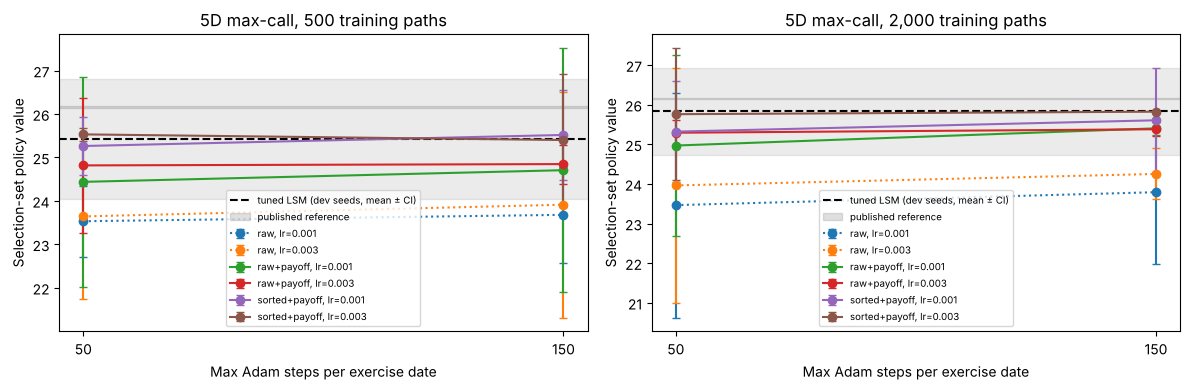

selection_value     gap  n_guarded  \
budget variant       lr    max_steps                                       
500    raw           0.001 50.0               23.5309  2.6281        6.0   
                           150.0              23.6785  2.4805        5.0   
                     0.003 50.0               23.6416  2.5174        5.0   
                           150.0              23.9118  2.2472        3.0   
       raw+payoff    0.001 50.0               24.4373  1.7217        4.0   
                           150.0              24.7060  1.4530        2.5   
                     0.003 50.0               24.8163  1.3427        3.0   
                           150.0              24.8464  1.3126        1.0   
       sorted+payoff 0.001 50.0               25.2626  0.8964        3.0   
                           150.0              25.5170  0.6420        2.0   
                     0.003 50.0               25.5303  0.6287        2.5   
                           150.0              25.4000  0.7590        1.5   
2000   raw           0.001 50.0               23.4642  2.6948        5.0   
                           150.0              23.7903  2.3687        3.5   
                     0.003 50.0               23.9615  2.1975        3.5   
                           150.0              24.2511  1.9079        0.5   
       raw+payoff    0.001 50.0               24.9682  1.1908        3.5   
                           150.0              25.4026  0.7564        2.0   
                     0.003 50.0               25.2914  0.8676        1.5   
                           150.0              25.3791  0.7799        1.5   
       sorted+payoff 0.001 50.0               25.3194  0.8396        3.5   
                           150.0              25.6054  0.5536        2.5   
                     0.003 50.0               25.7595  0.3995        2.0   
                           150.0              25.8224  0.3366        1.0   

                                      at_limit_share   fit_s  
budget variant       lr    max_steps                          
500    raw           0.001 50.0               0.8125  0.3375  
                           150.0              0.3750  0.9875  
                     0.003 50.0               0.8750  0.3401  
                           150.0              0.2500  0.9856  
       raw+payoff    0.001 50.0               0.8750  0.3333  
                           150.0              0.3125  1.0117  
                     0.003 50.0               0.7500  0.3471  
                           150.0              0.1250  0.9668  
       sorted+payoff 0.001 50.0               0.8750  0.7521  
                           150.0              0.3750  0.9867  
                     0.003 50.0               0.6250  0.3467  
                           150.0              0.0000  1.0160  
2000   raw           0.001 50.0               0.8125  0.3377  
                           150.0              0.5000  1.0075  
                     0.003 50.0               0.8125  0.3505  
                           150.0              0.2500  1.0413  
       raw+payoff    0.001 50.0               1.0000  0.3506  
                           150.0              0.5000  0.9620  
                     0.003 50.0               0.6250  0.3436  
                           150.0              0.1875  0.9843  
       sorted+payoff 0.001 50.0               0.8125  0.3527  
                           150.0              0.5000  1.0150  
                     0.003 50.0               0.8125  0.3618  
                           150.0              0.3125  1.0126

In [3]:
nn_df = cal_df[cal_df.method == "nn"]
fig, axes = plt.subplots(1, len(cal["budgets"]), figsize=(6 * len(cal["budgets"]), 4), squeeze=False)
for ax, budget in zip(axes[0], cal["budgets"]):
    lsm_vals = cal_df[(cal_df.method == "lsm") & (cal_df.budget == budget)].selection_value
    m, _, lo, hi = mean_ci(lsm_vals)
    if np.isfinite(lo):
        ax.axhspan(lo, hi, color="black", alpha=0.08)
    ax.axhline(m, color="black", ls="--", label="tuned LSM (dev seeds, mean ± CI)")
    ax.axhspan(ref["low"], ref["high"], color="grey", alpha=0.25, label="published reference")
    for (variant, lr), sub in nn_df[nn_df.budget == budget].groupby(["variant", "lr"]):
        stats = sub.groupby("max_steps").selection_value.apply(lambda s: pd.Series(mean_ci(s), index=["m", "se", "lo", "hi"])).unstack()
        err = np.vstack([stats.m - stats.lo, stats.hi - stats.m]) if stats.lo.notna().all() else None
        ax.errorbar(stats.index, stats.m, yerr=err, fmt="o:" if variant in cal["diagnostic_variants"] else "o-",
                    capsize=3, label=f"{variant}, lr={lr:g}")
    ax.set(xscale="log", xlabel="Max Adam steps per exercise date", ylabel="Selection-set policy value",
           title=f"5D max-call, {budget:,} training paths")
    ax.set_xticks(cal["max_steps"], [f"{s:,}" for s in cal["max_steps"]]); ax.minorticks_off()
    ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "calibration_saturation.png", dpi=160); plt.show()
(nn_df.groupby(["budget", "variant", "lr", "max_steps"])
      [["selection_value", "gap", "n_guarded", "at_limit_share", "fit_s"]].mean().round(4))

## 3. Pre-specified selection rule → `frozen_settings.json`
Written down before looking at any main-study result:

1. A *cell* is one (selection-rule variant, budget). For each candidate (learning rate, step limit), take its mean selection-set value over development seeds in every cell.
2. A candidate is **adequate** if, in every cell, it is within `tolerance` of the best candidate for that cell.
3. Choose the adequate candidate with the **fewest steps** (ties: higher average value). If none is adequate, choose the highest average value.
4. **Saturation flag:** for the chosen learning rate, if the largest step limit beats the second largest by more than `tolerance` in any cell (diagnostic variant included), it is flagged and must be reported.

`tolerance` is a pre-specified *practical* threshold, not a statistical test. The table after the rule shows each improvement with its interval across development seeds
(paired: both step limits are evaluated on the same selection-set paths and the same training data per seed). With few development seeds these intervals are wide.

In [ ]:
tol = cal["tolerance"]
sel_df = nn_df[nn_df.role == "selection"]
means = sel_df.groupby(["variant", "budget", "lr", "max_steps"]).selection_value.mean().unstack(["variant", "budget"])
best_per_cell = means.max(axis=0)
adequate = (means >= best_per_cell - tol).all(axis=1)
average = means.mean(axis=1)
candidates = average[adequate] if adequate.any() else average
order = sorted(candidates.index, key=lambda c: (c[1] if adequate.any() else 0, -candidates[c]))
lr_star, steps_star = order[0]

# Improvement of the largest over the second-largest step limit, per dev seed, for the chosen learning rate
steps_sorted = sorted(cal["max_steps"])
sat_rows = []
if len(steps_sorted) >= 2:
    chosen = nn_df[nn_df.lr == lr_star].pivot_table(index=["variant", "budget", "dev_seed"], columns="max_steps", values="selection_value")
    per_seed = (chosen[steps_sorted[-1]] - chosen[steps_sorted[-2]]).rename("improvement").reset_index()
    for (variant, budget), sub in per_seed.groupby(["variant", "budget"]):
        m, se, lo, hi = mean_ci(sub.improvement)
        sat_rows.append(dict(cell=f"{variant}@{budget}", role="selection" if variant in cal["variants"] else "diagnostic",
                             improvement=m, ci_low=lo, ci_high=hi, dev_seeds=len(sub), flagged=bool(m > tol)))
sat_df = pd.DataFrame(sat_rows)
not_saturated = {r.cell: r.improvement for r in sat_df.itertuples() if r.flagged}

frozen = dict(provenance=calibration_provenance(MODE), calibration_file=cal_path.name, neural=asdict(NeuralSettings(max_steps=int(steps_star), lr=float(lr_star), batch=cal["batch"])),
              rule=f"fewest steps within {tol} of the best in every (selection variant, budget) cell",
              selection_variants=cal["variants"], diagnostic_variants=cal["diagnostic_variants"],
              any_adequate=bool(adequate.any()),
              saturation=sat_rows, not_saturated_cells=not_saturated,
              development_cost_cpu_minutes=float(cal_df.fit_s.sum() / 60),
              development_elapsed_minutes=float(cal_df.row_wall_s.sum() / 60),
              selection_set_paths=cal["selection_set"], dev_seeds=cal["dev_seeds"], mode=MODE)
(OUT / "frozen_settings.json").write_text(json.dumps(frozen, indent=2))
print("Frozen neural settings:", frozen["neural"])
print(f"Improvement of {steps_sorted[-1]} over {steps_sorted[-2]} steps (lr={lr_star:g}), across development seeds:")
display(sat_df.round(4))
if not_saturated:
    print("WARNING: training still improves at the largest step limit in", list(not_saturated),
          "\n -> report this. If a SELECTION variant is flagged, consider adding a larger step limit to CONFIG and "
          "rerunning this notebook BEFORE notebook 03. A flagged DIAGNOSTIC variant is a finding (Claim B), not a blocker.")

## 4. Preflight (opt-in): runtime projection for notebook 03
Times one complete unit (LSM selection + every neural variant planned at that budget + evaluation on a test-sized set of non-test paths) per main budget,
using the frozen settings and a development seed. Set `RUN_PREFLIGHT = True` once, deliberately; the result is saved to `preflight.json` and shown by notebook 03.

In [5]:
RUN_PREFLIGHT = False   # set True once before the full main study (takes a few minutes in full mode)
study = CONFIG[MODE]["study"]
pre_path = OUT / "preflight.json"
if RUN_PREFLIGHT:
    settings = NeuralSettings(**frozen["neural"])
    unit_s = {}
    for d, budgets in ((5, study["budgets"]), (2, [study["case_2d"]["budget"]])):
        o = paper_max_call(d)
        test_like = gbm_paths(o, study["test"], seed_for(BASE, "holdout", d, extra=1))
        for b in budgets:
            variants = list(VARIANTS) if (d == 5 and b in study["ablation_budgets"]) else [MAIN_VARIANT]
            t0 = time.perf_counter()
            run_unit(o, b, 999, variants, settings, study["val"], test_like, reference_for(o), BASE)
            unit_s[f"{d}d@{b}"] = time.perf_counter() - t0
            print(f"{d}D, {b:>6} paths, {len(variants)} neural variant(s): {unit_s[f'{d}d@{b}']:.1f} s per seed")
    projected = sum(unit_s[f"5d@{b}"] for b in study["budgets"]) * len(study["seeds"]) + \
                unit_s[f"2d@{study['case_2d']['budget']}"] * len(study["case_2d"]["seeds"])
    pre_path.write_text(json.dumps(dict(neural=frozen["neural"], unit_seconds=unit_s, projected_minutes=projected / 60,
                                        note="10D extension not included in the projection"), indent=2))
if pre_path.exists():
    print(pre_path.read_text())
else:
    print("No preflight yet. Set RUN_PREFLIGHT = True and run this cell when you are ready for the full main study.")

No preflight yet. Set RUN_PREFLIGHT = True and run this cell when you are ready for the full main study.
